# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Maria Putu Evelyne Corena Puryatma | 5054251011 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [185]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# numpy 2.2 di Mac Apple Silicon kadang memunculkan RuntimeWarning palsu saat
# menghitung jarak (misalnya di silhouette_score). Hasilnya tetap benar, jadi warning ini disembunyikan.
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn.utils.extmath')

In [186]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pd.read_csv('Mall_Customers.csv')
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [187]:
print('Jumlah baris dan kolom:', df.shape)
df.info()

Jumlah baris dan kolom: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [188]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [189]:
print('Jumlah missing value per kolom:')
print(df.isnull().sum())

# CustomerID selalu unik, jadi df.duplicated() pasti 0.
# Cek juga duplikat tanpa CustomerID agar pengecekannya bermakna.
print('\nJumlah baris duplikat (semua kolom):', df.duplicated().sum())
print('Jumlah baris duplikat (tanpa CustomerID):', df.drop(columns='CustomerID').duplicated().sum())

# Pelanggan berbeda bisa saja punya Income dan Spending Score yang sama persis.
fitur = ['Annual Income (k$)', 'Spending Score (1-100)']
print('Jumlah pasangan nilai yang sama pada 2 fitur:', df[fitur].duplicated().sum())

Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat (semua kolom): 0
Jumlah baris duplikat (tanpa CustomerID): 0
Jumlah pasangan nilai yang sama pada 2 fitur: 4


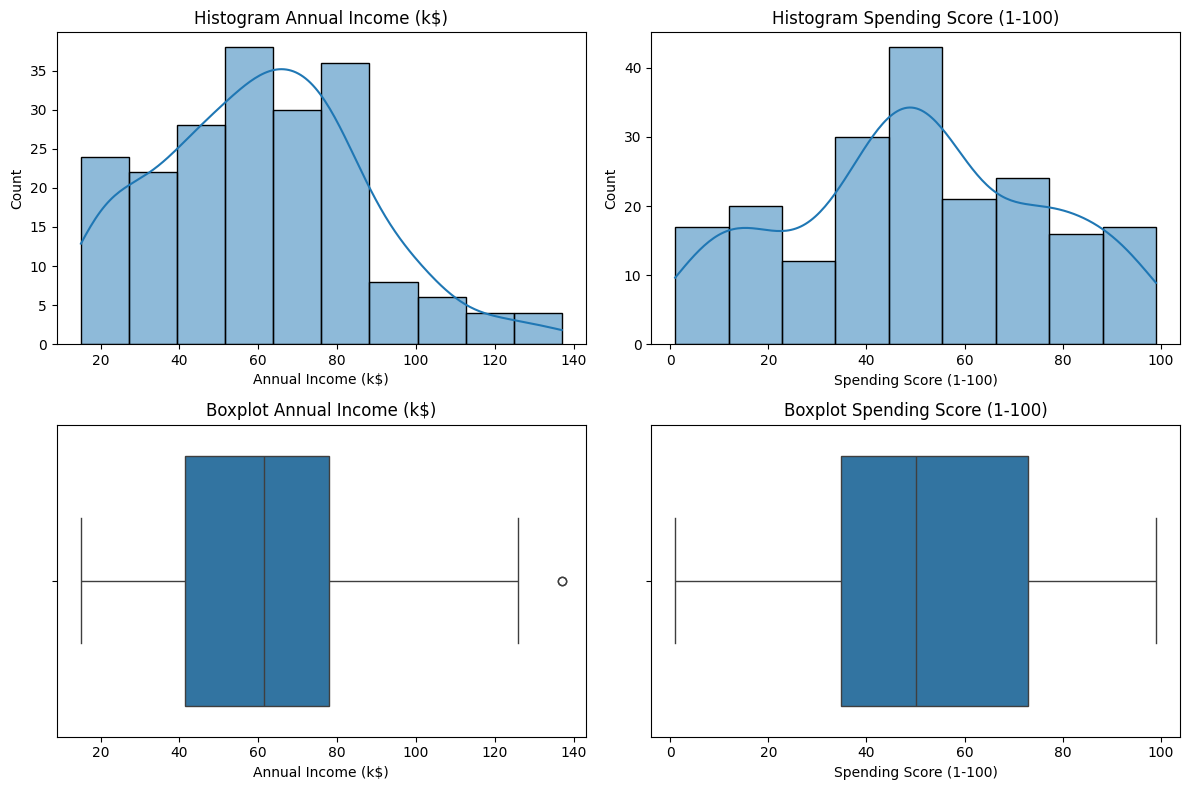

In [190]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(fitur):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f'Histogram {col}')
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

In [191]:
# Cek outlier dengan aturan IQR (sama seperti titik di luar "whisker" boxplot)
for col in fitur:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier = df[(df[col] < batas_bawah) | (df[col] > batas_atas)]
    print(f'{col}: rentang {df[col].min()}-{df[col].max()}, median {df[col].median()}, '
          f'Q1-Q3 {q1}-{q3}, batas IQR [{batas_bawah}, {batas_atas}]')
    print(f'  jumlah outlier: {len(outlier)} -> {outlier[col].tolist()}')

Annual Income (k$): rentang 15-137, median 61.5, Q1-Q3 41.5-78.0, batas IQR [-13.25, 132.75]
  jumlah outlier: 2 -> [137, 137]
Spending Score (1-100): rentang 1-99, median 50.0, Q1-Q3 34.75-73.0, batas IQR [-22.625, 130.375]
  jumlah outlier: 0 -> []


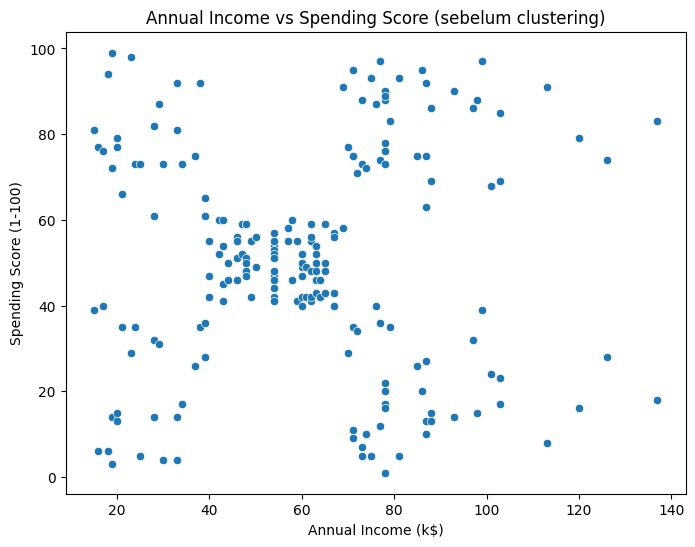

In [192]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=df)
plt.title('Annual Income vs Spending Score (sebelum clustering)')
plt.show()

In [193]:
# Nilai unik per kolom
print(df.nunique())

# Annual Income hanya punya 64 nilai unik untuk 200 pelanggan,
# jadi banyak pelanggan berbagi nilai income yang sama.
print('\nBerapa kali tiap nilai income muncul -> banyaknya nilai income:')
print(df['Annual Income (k$)'].value_counts().value_counts().sort_index())

CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64

Berapa kali tiap nilai income muncul -> banyaknya nilai income:
count
2     42
4     14
6      6
12     2
Name: count, dtype: int64


## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

1. Tidak ada missing value dan tidak ada baris duplikat.
2. Annual Income: 15–137 (median 61.5), ada 2 outlier (137). Spending Score: 1–99 (median 50), tidak ada outlier.
3. Ya, terlihat ±5 kelompok: 1 di tengah (income & spending sedang) dan 4 di pojok (kombinasi income rendah/tinggi dengan spending rendah/tinggi). Garis vertikal muncul karena banyak pelanggan punya income yang sama, bukan kelompok sendiri.

# 2. Preprocessing

In [194]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

# Tidak ada missing value & duplikat (lihat EDA), jadi tidak ada baris yang dihapus
print('Missing value:', df.isnull().sum().sum())
print('Duplikat (tanpa CustomerID):', df.drop(columns='CustomerID').duplicated().sum())

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
X


Missing value: 0
Duplikat (tanpa CustomerID): 0


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
195,120,79
196,126,28
197,126,74
198,137,18


In [195]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
print(X_scaled.head())
print(X_scaled.describe())

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980
       Annual Income (k$)  Spending Score (1-100)
count        2.000000e+02            2.000000e+02
mean        -2.131628e-16           -1.465494e-16
std          1.002509e+00            1.002509e+00
min         -1.738999e+00           -1.910021e+00
25%         -7.275093e-01           -5.997931e-01
50%          3.587926e-02           -7.764312e-03
75%          6.656748e-01            8.851316e-01
max          2.917671e+00            1.894492e+00


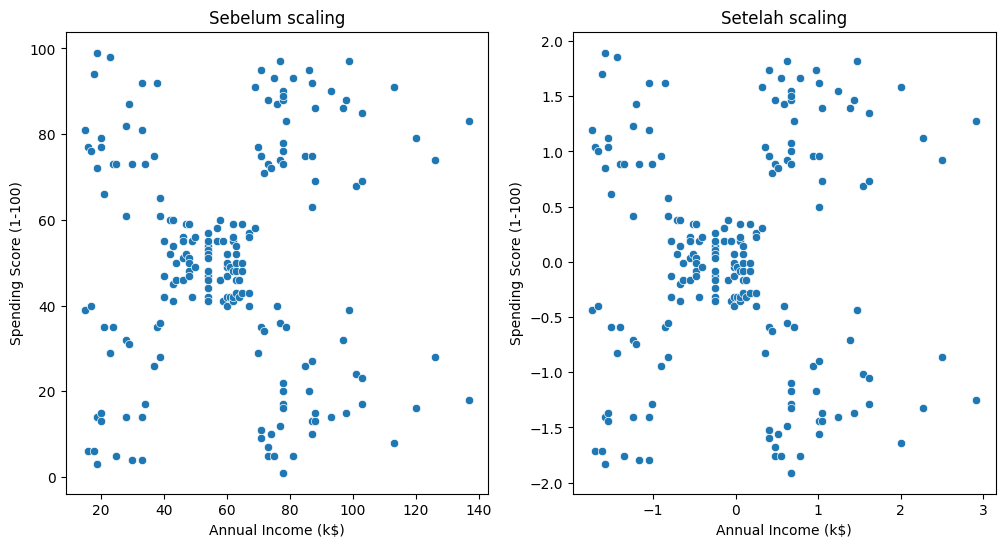

In [196]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=X, ax=axes[0])
axes[0].set_title('Sebelum scaling')
sns.scatterplot(x='Annual Income (k$)', y='Spending Score (1-100)', data=X_scaled, ax=axes[1])
axes[1].set_title('Setelah scaling')
plt.show()

1. Bentuk sebaran data sebelum dan sesudah scaling sama, cuma skalanya yang berubah (sekarang di sekitar 0).
2. Scaling penting karena DBSCAN, BIRCH, dan GMM pakai jarak. Kalau tidak di-scaling, fitur yang rentangnya lebih besar (Income) jadi lebih berpengaruh.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

1. Kedua fitur ini berupa angka, langsung menggambarkan kebiasaan belanja pelanggan, dan bisa digambar di grafik 2D.
2. CustomerID cuma nomor urut, tidak ada hubungannya dengan perilaku pelanggan, jadi tidak dipakai.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [197]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)


In [198]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

unique_labels, counts = np.unique(labels_dbscan, return_counts=True)
print('Label DBSCAN dan jumlah anggota masing-masing:')
for label, count in zip(unique_labels, counts):
    if label == -1:
        print(f'Label {label} (noise): {count} anggota')
    else:
        print(f'Label {label}: {count} anggota')

n_cluster_dbscan = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise_dbscan = (labels_dbscan == -1).sum()
print(f'\nJumlah cluster: {n_cluster_dbscan}')
print(f'Jumlah noise: {n_noise_dbscan}')

Label DBSCAN dan jumlah anggota masing-masing:
Label -1 (noise): 35 anggota
Label 0: 12 anggota
Label 1: 5 anggota
Label 2: 7 anggota
Label 3: 88 anggota
Label 4: 30 anggota
Label 5: 14 anggota
Label 6: 9 anggota

Jumlah cluster: 7
Jumlah noise: 35


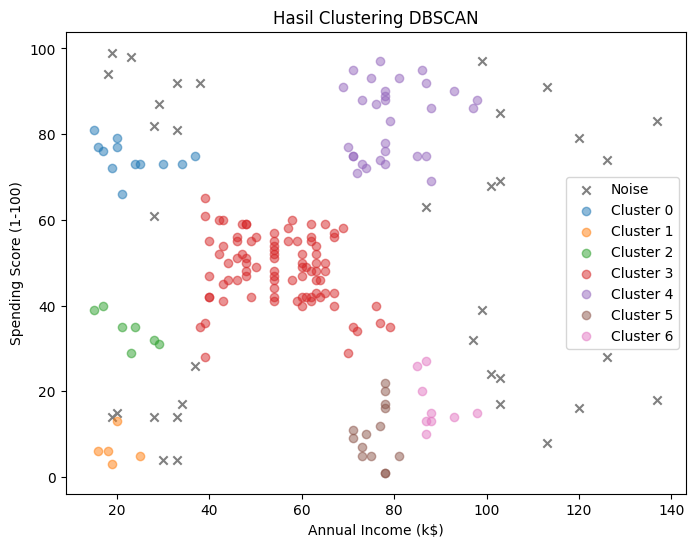

In [199]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(8, 6))
# Buat mask untuk noise
mask_noise = labels_dbscan == -1
# Plot noise dengan warna abu-abu dan tanda x agar beda dari warna cluster
plt.scatter(X.loc[mask_noise, 'Annual Income (k$)'], X.loc[mask_noise, 'Spending Score (1-100)'], c='gray', marker='x', label='Noise')
# Plot cluster dengan warna berbeda
for label in unique_labels:
    if label != -1:
        mask_cluster = labels_dbscan == label
        plt.scatter(X.loc[mask_cluster, 'Annual Income (k$)'], X.loc[mask_cluster, 'Spending Score (1-100)'], label=f'Cluster {label}', alpha=0.5)
plt.title('Hasil Clustering DBSCAN')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()

In [200]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

hasil_dbscan = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for min_samples in [3, 5, 7, 8, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()

        # Silhouette dihitung tanpa noise, dan hanya jika ada minimal 2 cluster
        mask = labels != -1
        if n_cluster >= 2 and n_cluster < mask.sum():
            sil = silhouette_score(X_scaled[mask], labels[mask])
        else:
            sil = np.nan

        hasil_dbscan.append({
            'eps': eps,
            'min_samples': min_samples,
            'jumlah_cluster': n_cluster,
            'jumlah_noise': n_noise,
            'persen_noise': round(n_noise / len(labels) * 100, 1),
            'silhouette': round(sil, 3),
        })

tabel_dbscan = pd.DataFrame(hasil_dbscan)
tabel_dbscan

,eps,min_samples,jumlah_cluster,jumlah_noise,persen_noise,silhouette
0,0.2,3,13,44,22.0,0.470
1,0.2,5,7,77,38.5,0.586
2,0.2,7,4,100,50.0,0.609
3,0.2,8,2,116,58.0,0.603
4,0.2,10,1,129,64.5,NaN
5,0.3,3,9,14,7.0,0.472
6,0.3,5,7,35,17.5,0.524
7,0.3,7,4,72,36.0,0.645
8,0.3,8,5,72,36.0,0.593
9,0.3,10,4,88,44.0,0.607


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

1. Semakin besar eps, noise makin sedikit dan cluster yang berdekatan jadi bergabung, jadi jumlah cluster berkurang. Di eps 0.6 semua data jadi 1 cluster.
2. Semakin besar min_samples, noise makin banyak karena syarat jadi titik inti lebih susah, dan cluster yang kecil bisa hilang.
3. Ada. eps 0.6 menghasilkan 1 cluster besar, sedangkan eps 0.2 dengan min_samples 10 noise-nya sampai 64.5%. Yang paling pas eps 0.4 dan min_samples 8 (5 cluster, noise 12.5%), jadi ini yang dipakai di evaluasi.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [201]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)


In [202]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
unique_labels_birch, counts_birch = np.unique(labels_birch, return_counts=True)
print('Label BIRCH dan jumlah anggota masing-masing:')
for label, count in zip(unique_labels_birch, counts_birch):
    print(f'Label {label}: {count} anggota')

n_cluster_birch = len(unique_labels_birch)
print(f'\nJumlah cluster: {n_cluster_birch}')


Label BIRCH dan jumlah anggota masing-masing:
Label 0: 36 anggota
Label 1: 109 anggota
Label 2: 8 anggota
Label 3: 25 anggota
Label 4: 22 anggota

Jumlah cluster: 5


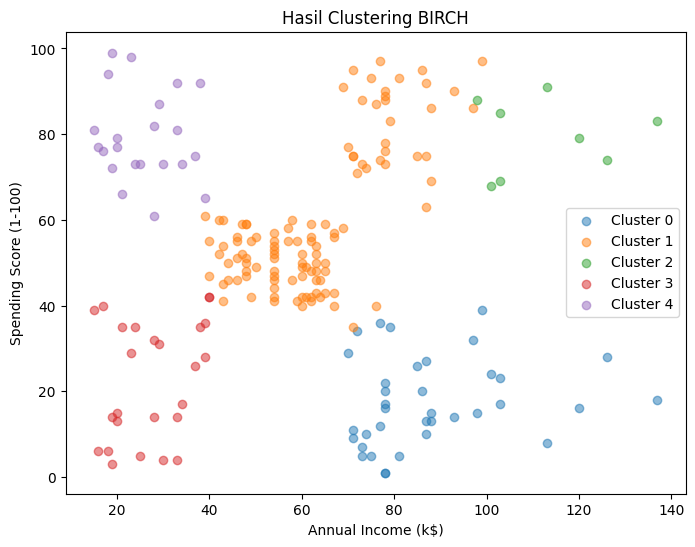

In [203]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plt.figure(figsize=(8, 6))
for label in unique_labels_birch:
    mask = labels_birch == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}', alpha=0.5)
plt.title('Hasil Clustering BIRCH')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()  

In [204]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

# Dicoba tanpa n_clusters (None) dan dengan n_clusters=5 untuk melihat pengaruhnya
hasil_birch = []
for n_clusters in [None, 5]:
    for threshold in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:
        model = Birch(threshold=threshold, n_clusters=n_clusters)
        labels = model.fit_predict(X_scaled)

        # BIRCH tidak menghasilkan noise (-1), jadi semua titik dipakai
        n_cluster = len(set(labels))
        if n_cluster >= 2 and n_cluster < len(labels):
            sil = silhouette_score(X_scaled, labels)
        else:
            sil = np.nan

        hasil_birch.append({
            'n_clusters': 'None' if n_clusters is None else n_clusters,
            'threshold': threshold,
            'jumlah_subcluster': len(model.subcluster_centers_),
            'jumlah_cluster': n_cluster,
            'silhouette': round(sil, 3),
        })

tabel_birch = pd.DataFrame(hasil_birch)
tabel_birch

/opt/miniconda3/lib/python3.13/site-packages/sklearn/cluster/_birch.py:730: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,n_clusters,threshold,jumlah_subcluster,jumlah_cluster,silhouette
0,None,0.1,83,83,0.336
1,None,0.2,39,39,0.401
2,None,0.3,23,23,0.414
3,None,0.5,10,10,0.477
4,None,0.7,6,6,0.486
5,None,1.0,4,4,0.389
6,5,0.1,83,5,0.554
7,5,0.2,39,5,0.554
8,5,0.3,23,5,0.478
9,5,0.5,10,5,0.414


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

1. Semakin besar threshold, subcluster makin sedikit karena lebih banyak titik digabung. Tanpa n_clusters, jumlah cluster turun dari 83 (threshold 0.1) jadi 4 (threshold 1.0).
2. BIRCH tidak punya noise, jadi titik yang jauh tetap dimasukkan ke cluster terdekat atau jadi cluster kecil sendiri. Kalau di DBSCAN, titik seperti itu langsung dianggap noise.
3. Iya. Tanpa n_clusters jumlah cluster tergantung threshold, sedangkan dengan n_clusters=5 hasilnya selalu 5 cluster (kecuali threshold 1.0 yang cuma dapat 4). Hasil paling bagus di threshold 0.1–0.2.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [205]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)


In [206]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

unique_labels_gmm, counts_gmm = np.unique(labels_gmm, return_counts=True)
print('Label GMM dan jumlah anggota masing-masing:')
for label, count in zip(unique_labels_gmm, counts_gmm):
    print(f'Label {label}: {count} anggota')

n_cluster_gmm = len(unique_labels_gmm)
print(f'\nJumlah cluster: {n_cluster_gmm}')

# Probabilitas keanggotaan tiap titik pada setiap cluster (P0-P4, totalnya 1)
proba_gmm = gmm.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba_gmm, columns=[f'P{i}' for i in range(n_cluster_gmm)]).round(3)
df_proba['label'] = labels_gmm
df_proba['proba_max'] = proba_gmm.max(axis=1).round(3)
print('\nContoh probabilitas keanggotaan:')
print(df_proba.head())

# Titik dianggap tidak pasti jika probabilitas terbesarnya < 0.8
tidak_pasti = df_proba[df_proba['proba_max'] < 0.8]
print(f'\nJumlah titik dengan keanggotaan tidak pasti (proba_max < 0.8): {len(tidak_pasti)}')
print(pd.concat([X.loc[tidak_pasti.index], tidak_pasti], axis=1).sort_values('proba_max'))

Label GMM dan jumlah anggota masing-masing:
Label 0: 84 anggota
Label 1: 39 anggota
Label 2: 21 anggota
Label 3: 33 anggota
Label 4: 23 anggota

Jumlah cluster: 5

Contoh probabilitas keanggotaan:
    P0   P1     P2   P3     P4  label  proba_max
0  0.0  0.0  0.001  0.0  0.999      4      0.999
1  0.0  0.0  1.000  0.0  0.000      2      1.000
2  0.0  0.0  0.000  0.0  1.000      4      1.000
3  0.0  0.0  1.000  0.0  0.000      2      1.000
4  0.0  0.0  0.002  0.0  0.998      4      0.998

Jumlah titik dengan keanggotaan tidak pasti (proba_max < 0.8): 6
     Annual Income (k$)  Spending Score (1-100)     P0   P1     P2     P3  \
124                  70                      29  0.497  0.0  0.000  0.503   
48                   40                      42  0.611  0.0  0.000  0.000   
49                   40                      42  0.611  0.0  0.000  0.000   
27                   28                      61  0.279  0.0  0.675  0.000   
160                  79                      35  0.772  0.

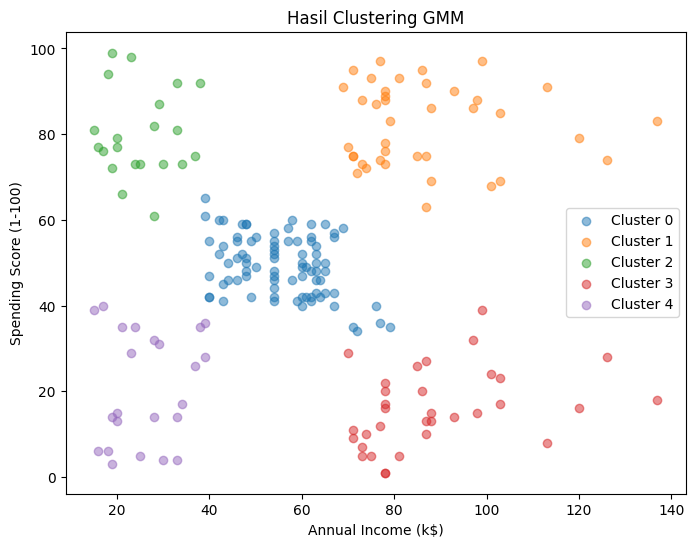

In [207]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(8, 6))
for label in np.unique(labels_gmm):
    mask = labels_gmm == label
    plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label=f'Cluster {label}', alpha=0.5)
plt.title('Hasil Clustering GMM')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.show()  

In [208]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

# Dicoba dengan covariance_type='full' (default) dan 'diag' untuk melihat pengaruhnya
hasil_gmm = []
for covariance_type in ['full', 'diag']:
    for n_components in range(2, 9):
        model = GaussianMixture(n_components=n_components, covariance_type=covariance_type, random_state=42)
        labels = model.fit_predict(X_scaled)
        bic = model.bic(X_scaled)

        # GMM tidak menghasilkan noise (-1), jadi semua titik dipakai
        n_cluster = len(set(labels))
        if n_cluster >= 2 and n_cluster < len(labels):
            sil = silhouette_score(X_scaled, labels)
        else:
            sil = np.nan

        hasil_gmm.append({
            'n_components': n_components,
            'covariance_type': covariance_type,
            'jumlah_cluster': n_cluster,
            'silhouette': round(sil, 3),
            'BIC': round(bic, 2),
        })

tabel_gmm = pd.DataFrame(hasil_gmm)
tabel_gmm

,n_components,covariance_type,jumlah_cluster,silhouette,BIC
0,2,full,2,0.379,1153.90
1,3,full,3,0.430,1151.72
2,4,full,4,0.413,1103.79
3,5,full,5,0.554,1058.65
4,6,full,6,0.517,1074.68
5,7,full,7,0.509,1087.33
6,8,full,8,0.430,1102.37
7,2,diag,2,0.356,1160.07
8,3,diag,3,0.439,1142.38
9,4,diag,4,0.482,1135.35


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

1. Probabilitas keanggotaan artinya seberapa yakin GMM bahwa suatu titik masuk ke tiap cluster. Kebanyakan titik sudah yakin (>0.9), tapi ada 6 titik yang ragu-ragu karena letaknya di perbatasan dua cluster.
2. Kalau n_components terlalu sedikit (2–4), kelompok yang beda jadi digabung. Kalau terlalu banyak (6–8), kelompok yang sama malah dipecah. Paling bagus di 5.
3. Karena GMM harus tahu dulu ada berapa distribusi Gaussian yang mau dicari mean dan kovariansnya.
4. Iya, n_components 5 punya silhouette paling tinggi dan BIC paling rendah.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [209]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluasi(X_data, labels):
    labels = np.asarray(labels)
    # Titik noise (-1) tidak ikut dihitung. BIRCH & GMM tidak punya noise, jadi semua titik dipakai.
    mask = labels != -1
    X_eval, labels_eval = X_data[mask], labels[mask]
    n_cluster = len(set(labels_eval))

    if n_cluster >= 2 and n_cluster < len(labels_eval):
        sil = silhouette_score(X_eval, labels_eval)
        dbi = davies_bouldin_score(X_eval, labels_eval)
        chi = calinski_harabasz_score(X_eval, labels_eval)
    else:
        sil, dbi, chi = np.nan, np.nan, np.nan

    return {
        'jumlah_cluster': n_cluster,
        'jumlah_noise': (~mask).sum(),
        'silhouette': round(sil, 3),
        'davies_bouldin': round(dbi, 3),
        'calinski_harabasz': round(chi, 2),
    }

In [210]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# Parameter terbaik dipilih dari tabel perbandingan di tiap bagian:
# - DBSCAN eps=0.4, min_samples=8: 5 cluster dengan noise 12.5%
# - BIRCH threshold=0.2, n_clusters=5: silhouette tertinggi (0.554)
# - GMM n_components=5, full: silhouette tertinggi & BIC terendah untuk covariance full
labels_dbscan_best = DBSCAN(eps=0.4, min_samples=8).fit_predict(X_scaled)
labels_birch_best = Birch(threshold=0.2, n_clusters=5).fit_predict(X_scaled)
labels_gmm_best = labels_gmm

hasil_terbaik = {
    'DBSCAN (eps=0.4, min_samples=8)': labels_dbscan_best,
    'BIRCH (threshold=0.2, n_clusters=5)': labels_birch_best,
    'GMM (n_components=5, full)': labels_gmm_best,
}

rows = []
for nama, labels in hasil_terbaik.items():
    hasil = evaluasi(X_scaled, labels)
    hasil['model'] = nama
    rows.append(hasil)

tabel_evaluasi = pd.DataFrame(rows).set_index('model')
tabel_evaluasi

,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
model,,,,,
"DBSCAN (eps=0.4, min_samples=8)",5,25,0.549,0.501,222.07
"BIRCH (threshold=0.2, n_clusters=5)",5,0,0.554,0.578,244.41
"GMM (n_components=5, full)",5,0,0.554,0.576,244.94


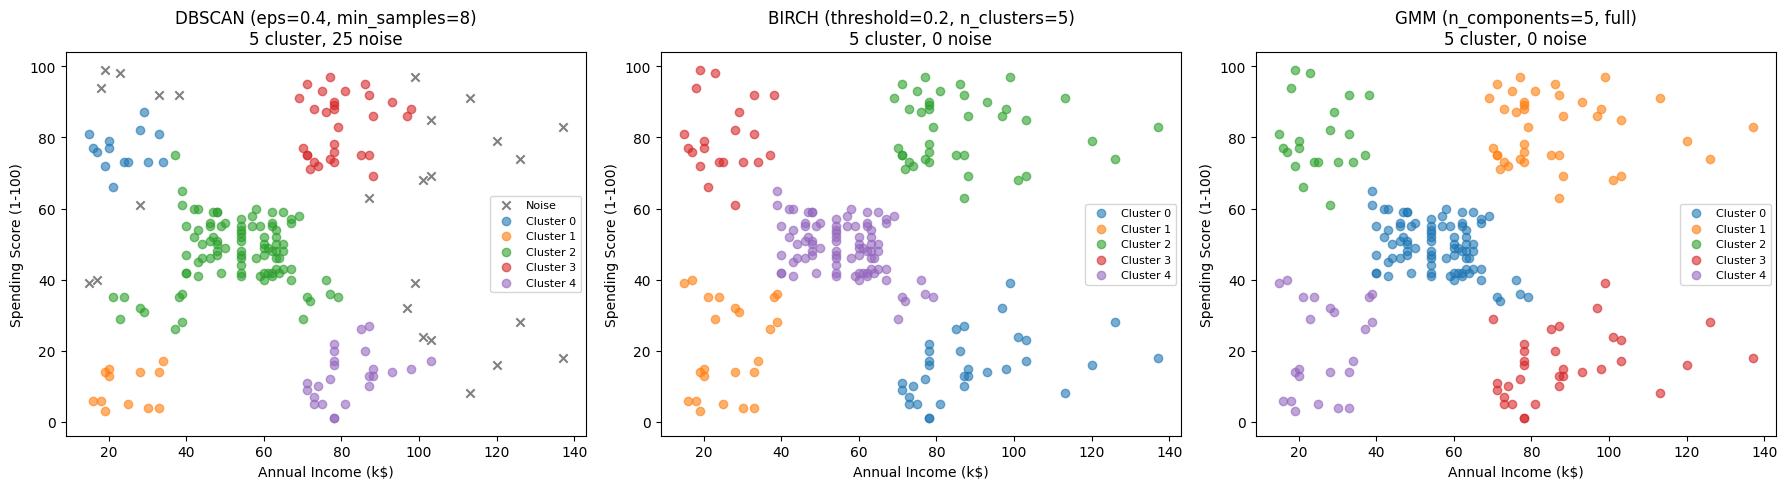

In [211]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nama, labels) in zip(axes, hasil_terbaik.items()):
    n_cluster = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    for label in np.unique(labels):
        mask = labels == label
        if label == -1:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                       c='gray', marker='x', label='Noise')
        else:
            ax.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                       alpha=0.6, label=f'Cluster {label}')
    ax.set_title(f'{nama}\n{n_cluster} cluster, {n_noise} noise')
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def profil_cluster(labels):
    data = X.copy()
    data['cluster'] = labels
    return data.groupby('cluster').agg(
        jumlah=('Annual Income (k$)', 'size'),
        income_median=('Annual Income (k$)', 'median'),
        income_mean=('Annual Income (k$)', 'mean'),
        spending_median=('Spending Score (1-100)', 'median'),
        spending_mean=('Spending Score (1-100)', 'mean'),
    ).round(1)

profil_dbscan = profil_cluster(labels_dbscan_best)
print('DBSCAN (tanpa noise)')
print(profil_dbscan.drop(index=-1))
print('\nDBSCAN: noise (label -1) ')
print(profil_dbscan.loc[[-1]])
print('Rentang nilai titik noise:')
print(X[labels_dbscan_best == -1].describe().loc[['min', 'max']])

print('\nBIRCH ')
print(profil_cluster(labels_birch_best))

print('\nGMM ')
print(profil_cluster(labels_gmm_best))

=== DBSCAN (tanpa noise) ===
         jumlah  income_median  income_mean  spending_median  spending_mean
cluster                                                                    
0            14           22.5         23.6             76.5           76.4
1            12           22.5         24.6              9.5            9.6
2            95           54.0         53.3             48.0           47.8
3            30           78.0         79.5             86.0           83.1
4            24           78.0         81.9             13.0           13.0

=== DBSCAN: noise (label -1) ===
         jumlah  income_median  income_mean  spending_median  spending_mean
cluster                                                                    
-1           25          101.0         83.0             68.0           60.5
Rentang nilai titik noise:
     Annual Income (k$)  Spending Score (1-100)
min                15.0                     8.0
max               137.0                    99.0

=== B

### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Opsional (n_clusters) | Ya |
| Dapat memberi label noise secara eksplisit? | Ya (-1) | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | eps, min_samples | threshold, n_clusters | n_components |
| Bentuk cluster yang dapat dimodelkan | Bebas, asal padat | Bulat | Elips |
| Kelebihan | Bisa mendeteksi noise | Cepat, cocok untuk data besar | Ada probabilitas keanggotaan, hasilnya paling rapi |
| Kekurangan | Sensitif ke eps & min_samples, noise-nya banyak | Tidak ada noise, threshold besar bikin cluster tergabung | Jumlah cluster harus ditentukan dulu |

Silhouette BIRCH dan GMM sama (0.554), DBSCAN sedikit di bawahnya (0.549). Davies-Bouldin DBSCAN paling bagus karena titik noise tidak ikut dihitung.

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

1. Supaya Income dan Spending Score punya skala yang sama, jadi waktu menghitung jarak tidak ada fitur yang lebih dominan.
2. eps besar → noise sedikit dan cluster bergabung (sampai jadi 1 cluster di eps 0.6). min_samples besar → noise makin banyak.
3. threshold besar → subcluster makin sedikit dan kelompok yang beda bisa tergabung. Dengan n_clusters, jumlah cluster akhirnya tetap 5 jadi lebih stabil.
4. Probabilitas menunjukkan seberapa yakin suatu titik masuk ke tiap cluster. EM memakainya berulang-ulang: E-step menghitung probabilitas tiap titik, lalu M-step memperbarui mean dan kovarians tiap cluster pakai probabilitas itu, sampai hasilnya tidak berubah lagi.
5. GMM, karena 5 cluster-nya sesuai dengan kelompok yang kelihatan di scatter plot EDA, semua titik dapat cluster, dan ada probabilitasnya juga.
6. Tidak sepenuhnya. Silhouette BIRCH dan GMM seri, Calinski-Harabasz paling tinggi GMM, tapi Davies-Bouldin paling bagus DBSCAN. Ini karena metrik DBSCAN dihitung tanpa 25 titik noise, jadi cluster-nya kelihatan lebih rapat.
7. Berdasarkan GMM:
   - Cluster 0 (84 orang): income ±55, spending ±50 → pelanggan biasa
   - Cluster 1 (39 orang): income ±79, spending ±83 → kaya dan boros (target utama)
   - Cluster 2 (21 orang): income ±24, spending ±77 → income rendah tapi boros
   - Cluster 3 (33 orang): income ±86, spending ±15 → kaya tapi hemat
   - Cluster 4 (23 orang): income ±25, spending ±17 → income rendah dan hemat
8. Dua fitur saja belum cukup menggambarkan pelanggan (umur dan gender tidak dipakai). Datanya juga cuma 200 orang, jadi hasilnya gampang berubah kalau parameternya diubah sedikit dan belum tentu berlaku untuk pelanggan lain.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

1. GMM paling berguna untuk data ini karena bisa memisahkan 5 kelompok pelanggan dengan jelas dan metriknya termasuk paling bagus (silhouette 0.554).
2. Parameter yang dipilih: DBSCAN eps 0.4 & min_samples 8 (satu-satunya yang dapat 5 cluster dengan noise sedikit), BIRCH threshold 0.2 & n_clusters 5 (silhouette paling tinggi), GMM n_components 5 (silhouette paling tinggi & BIC paling rendah).
3. DBSCAN mengelompokkan berdasarkan kepadatan dan bisa menandai noise, BIRCH merangkum data jadi subcluster lalu digabung, GMM memakai probabilitas dari distribusi Gaussian.
4. Eksperimen lanjutan: tambah fitur Age atau Gender, cari eps pakai k-distance plot, coba covariance_type lain di GMM, atau pakai data yang lebih banyak.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)